# Besoins en eau et efficacité de l'irrigation d'un périmètre irrigué
### Moulay Bousselham (Loukkos, Maroc) — données FAO WaPOR v3, 2018-2025

**Problématique.** Dans un périmètre irrigué, les cultures reçoivent-elles assez d'eau, trop, ou pas assez ? Où, et à quel moment de la saison ?

**Zone d'étude.** Une bande d'environ 6,5 × 3 km entre le cordon dunaire et la lagune de Merja Zerga, couverte par WaPOR au niveau 3 (pixels de 20 m, région « LOU »).

**Données.**
| Variable WaPOR | Signification | Résolution |
|---|---|---|
| L3-AETI-D | Évapotranspiration réelle et interception (ETR) | 20 m |
| L3-NPP-D | Production primaire nette (biomasse) | 20 m |
| L1-RET-D | Évapotranspiration de référence (ET0) | grossière |
| L1-PCP-D | Pluie | grossière |

L'occupation du sol (LCC) n'existe plus dans WaPOR v3 : elle est remplacée par la carte annuelle **Esri / Impact Observatory 10 m** et par une **digitalisation manuelle des serres**.

**Plan du notebook.**
0. Configuration
1. Téléchargement des données
2. Préparation : grille, occupation du sol, masques, cubes 2018-2025
3. Les quatre indicateurs
4. Classification K-means en deux niveaux
5. Figures clés
6. Conclusions et limites



## 0. Configuration

In [ ]:
# Packages, connexion au Drive et paramètres du projet
!pip install wapordl rasterio pystac-client planetary-computer -q

import os, glob, json, calendar
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, to_rgb
from matplotlib.patches import Patch
from rasterio.warp import reproject, Resampling, transform_bounds, transform_geom
from rasterio.transform import array_bounds
from rasterio.windows import from_bounds
from rasterio.features import rasterize
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import wapordl
import pystac_client, planetary_computer
from google.colab import drive

drive.mount('/content/drive')

dossier_projet = "/content/drive/MyDrive/Projet_WaPOR"
dossier_data = dossier_projet + "/data"
region = dossier_projet + "/zone_moulay_bousselham.geojson"
fichier_serres = dossier_projet + "/serres_moulay_bousselham.geojson"
variables = ["L3-AETI-D", "L3-NPP-D", "L1-RET-D", "L1-PCP-D"]
annees = list(range(2018, 2026))
os.makedirs(dossier_data, exist_ok=True)
print("✅ Configuration prête")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Configuration prête


In [ ]:
# Fonctions de lecture des données WaPOR
def jours_par_decade(annee):
    """Nombre de jours de chacune des 36 décades de l'année (la 3e décade va du 21 à la fin du mois)."""
    jours = []
    for mois in range(1, 13):
        nb_jours_mois = calendar.monthrange(annee, mois)[1]
        jours += [10, 10, nb_jours_mois - 20]
    return np.array(jours)

def lire_variable(annee, var):
    """Lit une variable WaPOR décadaire et la convertit en quantité par décade (mm ou gC/m²)."""
    fichier = glob.glob(f"{dossier_data}/{annee}/*{var}*.tif")[0]
    with rasterio.open(fichier) as src:
        donnees = src.read().astype(float)
        nodata = src.nodata
        echelles = np.array(src.scales).reshape(-1, 1, 1)
        decalages = np.array(src.offsets).reshape(-1, 1, 1)
        dates = src.descriptions
    if nodata is not None:
        donnees[donnees == nodata] = np.nan
    donnees = donnees * echelles + decalages                       # facteur d'échelle
    donnees = donnees * jours_par_decade(annee).reshape(-1, 1, 1)  # moyenne journalière -> total décadaire
    return donnees, dates

def grille_reference(annee):
    """Transformation, système de coordonnées et taille de la grille AETI à 20 m."""
    f = glob.glob(f"{dossier_data}/{annee}/*L3-AETI-D*.tif")[0]
    with rasterio.open(f) as src:
        return src.transform, src.crs, src.height, src.width

def lire_sur_grille(annee, var):
    """Lit une variable, la convertit et la ré-échantillonne (plus proche voisin) sur la grille de 20 m."""
    donnees, dates = lire_variable(annee, var)
    f = glob.glob(f"{dossier_data}/{annee}/*{var}*.tif")[0]
    with rasterio.open(f) as src:
        transform_src, crs_src = src.transform, src.crs
    transform_ref, crs_ref, hauteur, largeur = grille_reference(annee)
    if donnees.shape[1:] == (hauteur, largeur):
        return donnees, dates
    sortie = np.full((donnees.shape[0], hauteur, largeur), np.nan)
    reproject(source=donnees, destination=sortie,
              src_transform=transform_src, src_crs=crs_src,
              dst_transform=transform_ref, dst_crs=crs_ref,
              resampling=Resampling.nearest, src_nodata=np.nan, dst_nodata=np.nan)
    return sortie, dates

## 1. Téléchargement des données (FAO WaPOR v3, package `wapordl`)

Une année par dossier, pour éviter que les fichiers s'écrasent (leur nom ne contient pas la date) et pour pouvoir reprendre après une coupure : les fichiers déjà présents sont sautés.

In [ ]:
# Téléchargement 2018-2025 (reprise possible après coupure)
for annee in annees:
    dossier_annee = f"{dossier_data}/{annee}"
    os.makedirs(dossier_annee, exist_ok=True)
    periode = [f"{annee}-01-01", f"{annee}-12-31"]
    for var in variables:
        deja = [nom for nom in os.listdir(dossier_annee) if var in nom and nom.endswith(".tif")]
        if deja:
            print(f"⏭️ {annee} {var} : déjà téléchargé")
            continue
        try:
            f = wapordl.wapor_map(region, var, periode, dossier_annee)
            with rasterio.open(f) as src:
                print(f"✅ {annee} {var} : {src.count} décades")
        except Exception as erreur:
            print(f"❌ {annee} {var} : {erreur}")

⏭️ 2018 L3-AETI-D : déjà téléchargé
⏭️ 2018 L3-NPP-D : déjà téléchargé
⏭️ 2018 L1-RET-D : déjà téléchargé
⏭️ 2018 L1-PCP-D : déjà téléchargé
⏭️ 2019 L3-AETI-D : déjà téléchargé
⏭️ 2019 L3-NPP-D : déjà téléchargé
⏭️ 2019 L1-RET-D : déjà téléchargé
⏭️ 2019 L1-PCP-D : déjà téléchargé
⏭️ 2020 L3-AETI-D : déjà téléchargé
⏭️ 2020 L3-NPP-D : déjà téléchargé
⏭️ 2020 L1-RET-D : déjà téléchargé
⏭️ 2020 L1-PCP-D : déjà téléchargé
⏭️ 2021 L3-AETI-D : déjà téléchargé
⏭️ 2021 L3-NPP-D : déjà téléchargé
⏭️ 2021 L1-RET-D : déjà téléchargé
⏭️ 2021 L1-PCP-D : déjà téléchargé
⏭️ 2022 L3-AETI-D : déjà téléchargé
⏭️ 2022 L3-NPP-D : déjà téléchargé
⏭️ 2022 L1-RET-D : déjà téléchargé
⏭️ 2022 L1-PCP-D : déjà téléchargé
⏭️ 2023 L3-AETI-D : déjà téléchargé
⏭️ 2023 L3-NPP-D : déjà téléchargé
⏭️ 2023 L1-RET-D : déjà téléchargé
⏭️ 2023 L1-PCP-D : déjà téléchargé
⏭️ 2024 L3-AETI-D : déjà téléchargé
⏭️ 2024 L3-NPP-D : déjà téléchargé
⏭️ 2024 L1-RET-D : déjà téléchargé
⏭️ 2024 L1-PCP-D : déjà téléchargé
⏭️ 2025 L3-AE

In [ ]:
# Vérification : 8 années × 4 variables, 36 décades chacune
problemes = 0
for annee in annees:
    for var in variables:
        fichiers = glob.glob(f"{dossier_data}/{annee}/*{var}*.tif")
        if not fichiers:
            print(f"❌ {annee} {var} : fichier manquant")
            problemes += 1
        else:
            with rasterio.open(fichiers[0]) as src:
                if src.count != 36:
                    print(f"⚠️ {annee} {var} : {src.count} décades seulement")
                    problemes += 1
print("Nombre de problèmes :", problemes)

Nombre de problèmes : 0


## 2. Préparation des données

### 2.1 Grille de référence et contour de la zone
Les valeurs décadaires de WaPOR sont des moyennes journalières : elles sont multipliées par le nombre de jours de chaque décade (8 à 11 jours pour la 3e décade du mois). La pluie et la RET, à résolution grossière, sont ré-échantillonnées sur la grille AETI de 20 m.

Grille : 324 × 155 pixels de 20 m
AETI 2023 : moyenne 498 mm, min 108 mm, max 1219 mm


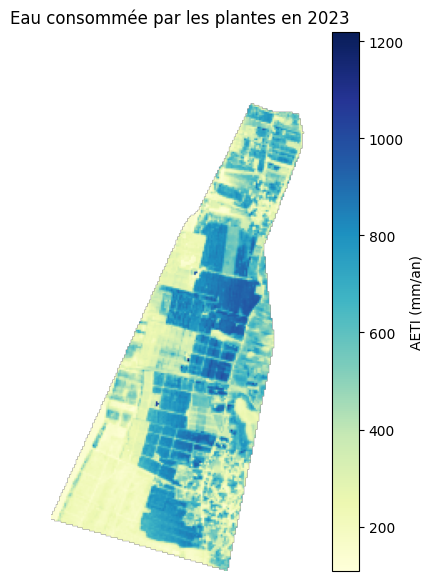

In [ ]:
# Grille de référence (AETI, 20 m) et consommation annuelle 2023
transform_ref, crs_ref, hauteur, largeur = grille_reference(2023)
aeti_2023, dates_2023 = lire_variable(2023, "L3-AETI-D")
dans_zone = ~np.isnan(aeti_2023[0])

total_2023 = np.sum(aeti_2023, axis=0)
print(f"Grille : {hauteur} × {largeur} pixels de 20 m")
print(f"AETI 2023 : moyenne {np.nanmean(total_2023):.0f} mm, "
      f"min {np.nanmin(total_2023):.0f} mm, max {np.nanmax(total_2023):.0f} mm")

plt.figure(figsize=(6, 7))
plt.imshow(total_2023, cmap="YlGnBu")
plt.colorbar(label="AETI (mm/an)")
plt.title("Eau consommée par les plantes en 2023")
plt.axis("off")
plt.show()

### 2.2 Occupation du sol : Esri / Impact Observatory 10 m
La LCC de WaPOR n'existe plus en v3 (erreur 404 sur `L2-LCC-A` et `L1-LCC-A`). On utilise la carte annuelle Esri (collection `io-lulc-annual-v02` du Microsoft Planetary Computer, disponible de 2018 à 2023), agrégée sur la grille de 20 m par la **classe majoritaire**. Seules les cartes dont la date de début correspond à l'année demandée sont retenues ; 2024 et 2025 utilisent la carte 2023.

Le serveur limitant le nombre de requêtes, cette étape n'est faite **qu'une seule fois** : si les masques sont déjà enregistrés dans le Drive (`masque_champ.npy`, `masque_serres.npy`), elle est sautée et le serveur n'est pas contacté.

In [ ]:
import time
fichier_lcc = dossier_projet + "/lcc_esri.npz"
bbox_gps = transform_bounds(crs_ref, "EPSG:4326", *array_bounds(hauteur, largeur, transform_ref))

def lire_esri(annee):
    """Carte Esri de l'année (codes de classes) sur la grille de 20 m, ou None si absente."""
    recherche = catalogue.search(collections=["io-lulc-annual-v02"], bbox=bbox_gps,
                                 datetime=f"{annee}-01-01/{annee}-12-31")
    items = [it for it in recherche.items()
             if it.properties.get("start_datetime", "")[:4] == str(annee)]
    if not items:
        return None
    carte = np.zeros((hauteur, largeur), dtype=np.uint8)
    for item in items:
        with rasterio.open(item.assets["data"].href) as src:
            b = transform_bounds("EPSG:4326", src.crs, *bbox_gps)
            fenetre = from_bounds(*b, transform=src.transform).round_offsets().round_lengths()
            morceau = src.read(1, window=fenetre, boundless=True, fill_value=0)
            temp = np.zeros_like(carte)
            reproject(source=morceau, destination=temp,
                      src_transform=src.window_transform(fenetre), src_crs=src.crs,
                      dst_transform=transform_ref, dst_crs=crs_ref,
                      resampling=Resampling.mode, src_nodata=0, dst_nodata=0)
        carte = np.where(carte == 0, temp, carte)
    carte[~dans_zone] = 0
    return carte

noms_esri = {1: "Eau", 2: "Arbres", 4: "Végétation inondée", 5: "Cultures",
             7: "Bâti", 8: "Sol nu", 11: "Parcours"}
couleurs_esri = {1: "#419bdf", 2: "#397d49", 4: "#7a87c6", 5: "#e49635",
                 7: "#c4281b", 8: "#a59b8f", 11: "#e3e2c3"}

fichiers_masques = [dossier_projet + "/masque_champ.npy", dossier_projet + "/masque_serres.npy"]
masques_deja_faits = all(os.path.exists(f) for f in fichiers_masques)

if masques_deja_faits:
    lcc_esri = {}
    print("✅ Masques déjà enregistrés dans le Drive : étape Esri sautée (serveur non contacté)")
elif os.path.exists(fichier_lcc):
    archive = np.load(fichier_lcc)
    lcc_esri = {int(a): archive[a] for a in archive.files}
    print("✅ Cartes Esri relues depuis le Drive :", sorted(lcc_esri))
else:
    for essai in range(5):
        try:
            catalogue = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                                                  modifier=planetary_computer.sign_inplace)
            lcc_esri = {}
            for annee in annees:
                carte = lire_esri(annee)
                if carte is None:
                    print(f"❌ {annee} : pas disponible")
                else:
                    lcc_esri[annee] = carte
            break
        except Exception as erreur:
            attente = 60 * (essai + 1)
            print(f"⏳ Serveur indisponible ({type(erreur).__name__}) : nouvel essai dans {attente} s")
            time.sleep(attente)
    else:
        raise RuntimeError("Planetary Computer toujours indisponible : relancez cette cellule plus tard.")
    np.savez_compressed(fichier_lcc, **{str(a): c for a, c in lcc_esri.items()})
    print("✅ Cartes Esri enregistrées dans le Drive")

for annee, carte in sorted(lcc_esri.items()):
    total = np.sum(carte > 0)
    texte = " | ".join(f"{noms_esri[c]} {100 * np.sum(carte == c) / total:.1f} %"
                       for c in noms_esri if np.any(carte == c))
    print(f"✅ {annee} : {texte}")

if lcc_esri:
    derniere = max(lcc_esri)
    image = np.ones((hauteur, largeur, 3))
    for code_c, coul in couleurs_esri.items():
        image[lcc_esri[derniere] == code_c] = to_rgb(coul)
    plt.figure(figsize=(6, 7))
    plt.imshow(image)
    plt.legend(handles=[Patch(color=couleurs_esri[c], label=noms_esri[c]) for c in couleurs_esri
                        if np.any(lcc_esri[derniere] == c)], loc="lower right", fontsize=8)
    plt.title(f"Occupation du sol Esri, {derniere}")
    plt.axis("off")
    plt.show()

✅ Masques déjà enregistrés dans le Drive : étape Esri sautée (serveur non contacté)


### 2.3 Masques : plein champ, serres, exclusions
Comparée à l'image satellite, la classe « bâti » d'Esri correspond surtout aux villages, tandis que la plupart des **serres** sont classées en « cultures ». Les 15 blocs de serres ont donc été **digitalisés à la main** (geojson.io). Sous plastique, le satellite observe la bâche et non la culture : les serres sont analysées à part.

- **Plein champ** = classe Esri « cultures » et hors serres (un masque par année)
- **Exclus** = villages, dunes, sol nu, arbres, eau

✅ Masques relus depuis le Drive
2018 : plein champ 61.5 % de la zone
2019 : plein champ 60.6 % de la zone
2020 : plein champ 61.9 % de la zone
2021 : plein champ 59.0 % de la zone
2022 : plein champ 68.7 % de la zone
2023 : plein champ 73.2 % de la zone
2024 : plein champ 73.2 % de la zone
2025 : plein champ 73.2 % de la zone
Serres : 10.5 % de la zone (85 ha)


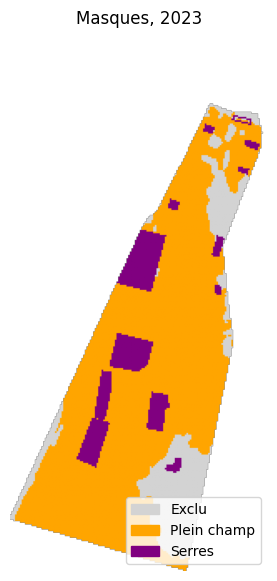

In [ ]:
# Masques "plein champ" (par année) et "serres" (fixe)
if masques_deja_faits:
    serres = np.load(dossier_projet + "/masque_serres.npy")
    masque_champ = dict(zip(annees, np.load(dossier_projet + "/masque_champ.npy")))
    print("✅ Masques relus depuis le Drive")
else:
    with open(fichier_serres) as f:
        geo = json.load(f)
    formes = [transform_geom("EPSG:4326", crs_ref, feat["geometry"]) for feat in geo["features"]]
    serres = rasterize(formes, out_shape=(hauteur, largeur), transform=transform_ref,
                       fill=0, default_value=1).astype(bool) & dans_zone
    print("Serres digitalisées :", len(formes))
    masque_champ = {}
    for annee in annees:
        annee_esri = annee if annee in lcc_esri else min(lcc_esri, key=lambda a: abs(a - annee))
        masque_champ[annee] = (lcc_esri[annee_esri] == 5) & ~serres
    np.save(dossier_projet + "/masque_serres.npy", serres)
    np.save(dossier_projet + "/masque_champ.npy", np.array([masque_champ[a] for a in annees]))
    np.save(dossier_projet + "/dans_zone.npy", dans_zone)
    print("✅ Masques enregistrés dans le Drive")

for annee in annees:
    print(f"{annee} : plein champ {100 * masque_champ[annee].sum() / dans_zone.sum():.1f} % de la zone")
print(f"Serres : {100 * serres.sum() / dans_zone.sum():.1f} % de la zone ({serres.sum() * 0.04:.0f} ha)")

categorie = np.full((hauteur, largeur), np.nan)
categorie[dans_zone] = 0
categorie[masque_champ[2023]] = 1
categorie[serres] = 2
plt.figure(figsize=(6, 7))
plt.imshow(categorie, cmap=ListedColormap(["lightgrey", "orange", "purple"]), vmin=0, vmax=2)
plt.legend(handles=[Patch(color="lightgrey", label="Exclu"),
                    Patch(color="orange", label="Plein champ"),
                    Patch(color="purple", label="Serres")], loc="lower right")
plt.title("Masques, 2023")
plt.axis("off")
plt.show()

### 2.4 Cubes 2018-2025 et campagnes agricoles
Chaque variable est rassemblée en un cube de 288 décades (8 ans × 36). L'analyse se fait par **campagne agricole** (septembre → août) : 7 campagnes complètes, de 2018-19 à 2024-25.

In [ ]:
# Cubes 2018-2025 (calculés une fois, puis relus depuis le Drive)
cubes = {}
for var in variables:
    chemin = f"{dossier_projet}/cube_{var}.npy"
    if os.path.exists(chemin):
        cubes[var] = np.load(chemin)
    else:
        cubes[var] = np.concatenate([lire_sur_grille(a, var)[0].astype(np.float32)
                                     for a in annees], axis=0)
        np.save(chemin, cubes[var])
    print(f"✅ {var} : {cubes[var].shape}")

dates_toutes = pd.to_datetime([f"{a}-{m:02d}-{j:02d}"
                               for a in annees for m in range(1, 13) for j in (1, 11, 21)])
masque_288 = np.repeat(np.array([masque_champ[a] for a in annees]), 36, axis=0)

campagne = np.where(dates_toutes.month >= 9, dates_toutes.year, dates_toutes.year - 1)
campagnes = list(range(2018, 2025))
nom_campagne = {c: f"{c}-{str(c + 1)[2:]}" for c in campagnes}
ete = dates_toutes.month.isin([6, 7, 8])
hiver = dates_toutes.month.isin([12, 1, 2])

aeti = cubes["L3-AETI-D"]
ret = cubes["L1-RET-D"]
pluie = cubes["L1-PCP-D"]
print("Campagnes :", list(nom_campagne.values()))

✅ L3-AETI-D : (288, 324, 155)
✅ L3-NPP-D : (288, 324, 155)
✅ L1-RET-D : (288, 324, 155)
✅ L1-PCP-D : (288, 324, 155)
Campagnes : ['2018-19', '2019-20', '2020-21', '2021-22', '2022-23', '2023-24', '2024-25']


## 3. Les quatre indicateurs

### 3.1 ET relative (AETI ÷ RET)
ETR ÷ ET0 = Kc × taux de satisfaction : une valeur basse peut traduire un manque d'eau **ou** un faible couvert (culture jeune, parcelle récoltée). Le seuil de 0,7 des consignes est d'abord testé tel quel.

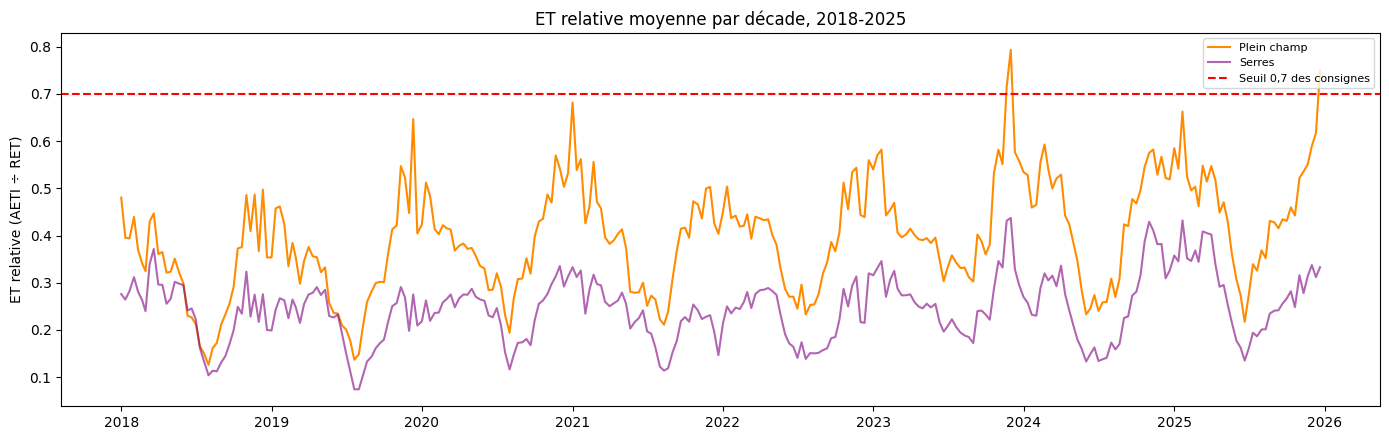

In [ ]:
# ET relative brute : plein champ et serres
etrel = aeti / ret
etrel_champ = np.where(masque_288, etrel, np.nan)
etrel_serres = np.where(serres, etrel, np.nan)

plt.figure(figsize=(14, 4.5))
plt.plot(dates_toutes, np.nanmean(etrel_champ, axis=(1, 2)), color="darkorange", label="Plein champ")
plt.plot(dates_toutes, np.nanmean(etrel_serres, axis=(1, 2)), color="purple", alpha=0.6, label="Serres")
plt.axhline(0.7, color="red", linestyle="--", label="Seuil 0,7 des consignes")
plt.ylabel("ET relative (AETI ÷ RET)")
plt.title("ET relative moyenne par décade, 2018-2025")
plt.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

Même les meilleures parcelles restent sous 0,7 en été : le seuil ne convient pas à cette zone côtière (RET probablement surestimée par des pixels grossiers, vergers au goutte-à-goutte à Kc bas). Chaque pixel est donc comparé aux **5 % meilleurs pixels de plein champ de la même décade** (95e percentile), ce qui neutralise l'erreur commune sur la RET.

Référence moyenne en été : 0.54 | en hiver : 0.76


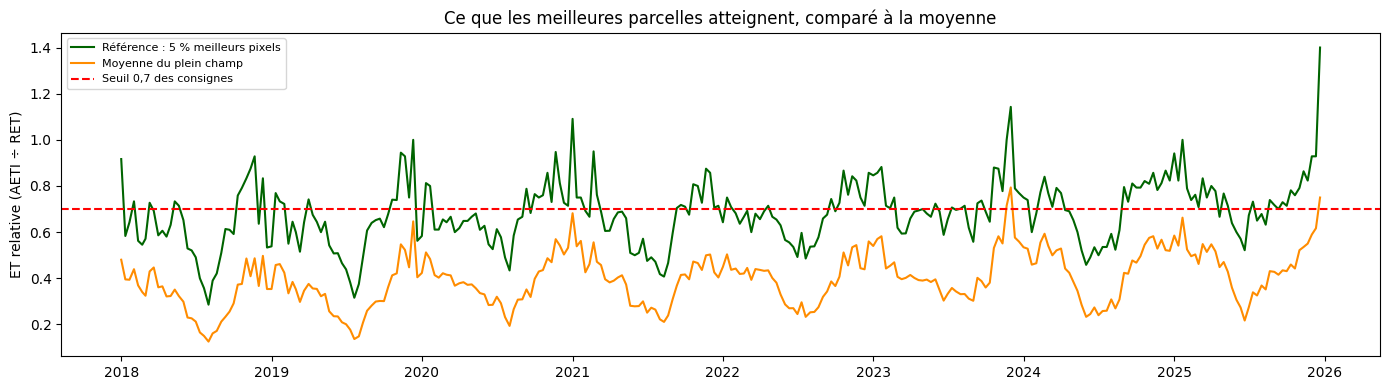

/tmp/ipykernel_2136/4201601617.py:18: RuntimeWarning: Mean of empty slice
  carte = np.nanmean(etrel_ref[ete & (campagne == c)], axis=0)


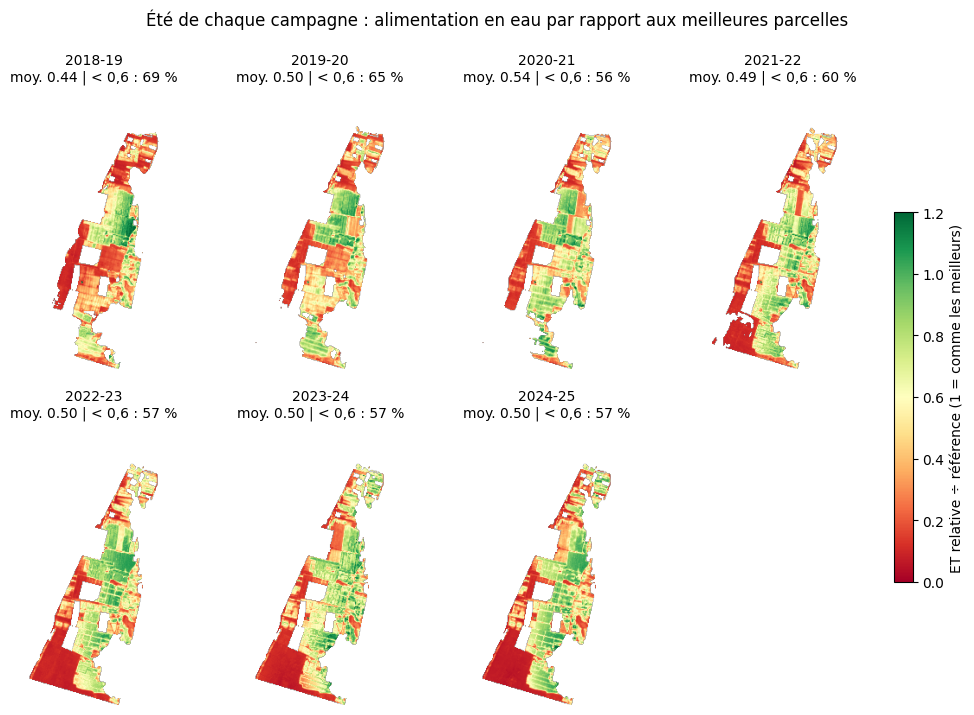

In [ ]:
# ET relative par rapport à la référence locale (95e percentile)
reference = np.nanpercentile(etrel_champ, 95, axis=(1, 2))
etrel_ref = etrel_champ / reference[:, None, None]
print(f"Référence moyenne en été : {np.mean(reference[ete]):.2f} | en hiver : {np.mean(reference[hiver]):.2f}")

plt.figure(figsize=(14, 4))
plt.plot(dates_toutes, reference, color="darkgreen", label="Référence : 5 % meilleurs pixels")
plt.plot(dates_toutes, np.nanmean(etrel_champ, axis=(1, 2)), color="darkorange", label="Moyenne du plein champ")
plt.axhline(0.7, color="red", linestyle="--", label="Seuil 0,7 des consignes")
plt.ylabel("ET relative (AETI ÷ RET)")
plt.title("Ce que les meilleures parcelles atteignent, comparé à la moyenne")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(14, 8))
for i, c in enumerate(campagnes):
    carte = np.nanmean(etrel_ref[ete & (campagne == c)], axis=0)
    pct_faible = 100 * np.sum(carte < 0.6) / np.sum(~np.isnan(carte))
    ax = axes.flat[i]
    im = ax.imshow(carte, cmap="RdYlGn", vmin=0, vmax=1.2)
    ax.set_title(f"{nom_campagne[c]}\nmoy. {np.nanmean(carte):.2f} | < 0,6 : {pct_faible:.0f} %", fontsize=10)
    ax.axis("off")
axes.flat[7].axis("off")
fig.colorbar(im, ax=axes, shrink=0.6, label="ET relative ÷ référence (1 = comme les meilleurs)")
plt.suptitle("Été de chaque campagne : alimentation en eau par rapport aux meilleures parcelles")
plt.show()

### 3.2 Apport d'irrigation estimé (AETI − pluie efficace)
Pluie efficace = 80 % de la pluie (méthode simple de la FAO), calcul par décade sans valeurs négatives. Il s'agit de l'irrigation **consommée** (besoins nets satisfaits) ; l'eau prélevée est plus élevée.

          Pluie (mm)  Eau consommée AETI (mm)  Irrigation estimée (mm)  \
Campagne                                                                 
2018-19        461.0                    388.0                    253.0   
2019-20        396.0                    448.0                    299.0   
2020-21        757.0                    442.0                    248.0   
2021-22        371.0                    493.0                    342.0   
2022-23        436.0                    540.0                    396.0   
2023-24        540.0                    503.0                    327.0   
2024-25        382.0                    556.0                    367.0   

          Irrigation (m³/ha)  
Campagne                      
2018-19               2526.0  
2019-20               2992.0  
2020-21               2484.0  
2021-22               3425.0  
2022-23               3964.0  
2023-24               3269.0  
2024-25               3668.0  


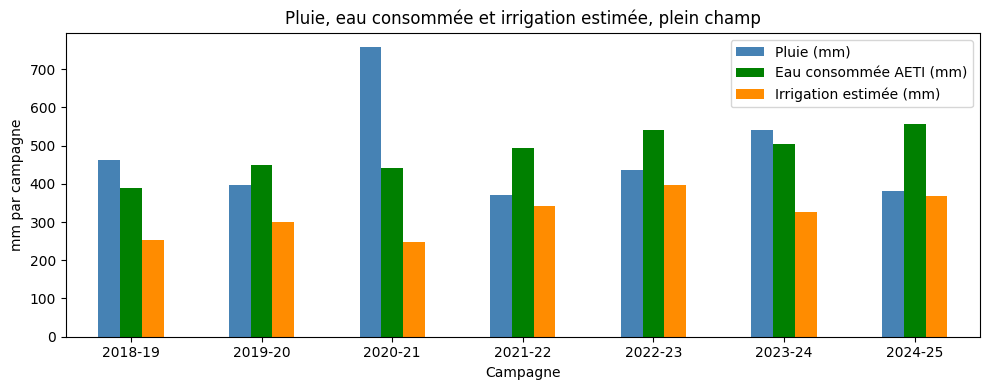

In [ ]:
# Apport d'irrigation par campagne, plein champ
irrigation = np.maximum(aeti - 0.8 * pluie, 0)

def total_campagne(cube, c):
    """Total sur la campagne, moyenne sur le plein champ (mm)."""
    sel = campagne == c
    return np.nanmean(np.sum(np.where(masque_288[sel], cube[sel], np.nan), axis=0))

tableau = pd.DataFrame([{"Campagne": nom_campagne[c],
                         "Pluie (mm)": total_campagne(pluie, c),
                         "Eau consommée AETI (mm)": total_campagne(aeti, c),
                         "Irrigation estimée (mm)": total_campagne(irrigation, c)}
                        for c in campagnes]).set_index("Campagne")
tableau["Irrigation (m³/ha)"] = tableau["Irrigation estimée (mm)"] * 10
print(tableau.round(0))

tableau.iloc[:, :3].plot(kind="bar", figsize=(10, 4), color=["steelblue", "green", "darkorange"])
plt.ylabel("mm par campagne")
plt.title("Pluie, eau consommée et irrigation estimée, plein champ")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 3.3 Productivité de l'eau (biomasse ÷ AETI)
NPP (gC/m²) × 22,222 = biomasse sèche totale (kg/ha), divisée par l'eau consommée (m³/ha). Les valeurs absolues incluent les racines et sont à interpréter avec prudence ; les comparaisons entre campagnes sont fiables.

In [ ]:
# Productivité de l'eau par campagne, plein champ
biomasse = cubes["L3-NPP-D"] * 22.222
tab_pe = pd.DataFrame([{"Campagne": nom_campagne[c],
                        "Biomasse (t/ha)": total_campagne(biomasse, c) / 1000,
                        "Eau consommée (m³/ha)": total_campagne(aeti, c) * 10}
                       for c in campagnes]).set_index("Campagne")
tab_pe["Productivité (kg/m³)"] = tab_pe["Biomasse (t/ha)"] * 1000 / tab_pe["Eau consommée (m³/ha)"]
print(tab_pe.round(2))

          Biomasse (t/ha)  Eau consommée (m³/ha)  Productivité (kg/m³)
Campagne                                                              
2018-19         16.379999            3882.939941                  4.22
2019-20         19.620001            4479.490234                  4.38
2020-21         19.270000            4417.939941                  4.36
2021-22         20.580000            4934.390137                  4.17
2022-23         22.969999            5398.350098                  4.26
2023-24         22.639999            5034.080078                  4.50
2024-25         24.020000            5559.919922                  4.32


### 3.4 Uniformité (coefficient de variation de l'AETI entre pixels)
Repères : < 10 % bonne, 10-25 % moyenne, > 25 % faible. Calculé ici sur tout le plein champ ; il est recalculé sur les seuls pixels irrigués après le K-means (section 4).

In [ ]:
# Coefficient de variation de la consommation entre pixels, par campagne
lignes_cv = []
for c in campagnes:
    sel = campagne == c
    eau_pixel = np.sum(np.where(masque_288[sel], aeti[sel], np.nan), axis=0)
    lignes_cv.append({"Campagne": nom_campagne[c], "Moyenne (mm)": np.nanmean(eau_pixel),
                      "Écart-type (mm)": np.nanstd(eau_pixel),
                      "CV (%)": 100 * np.nanstd(eau_pixel) / np.nanmean(eau_pixel)})
tab_cv = pd.DataFrame(lignes_cv).set_index("Campagne")
print(tab_cv.round(1))

          Moyenne (mm)  Écart-type (mm)     CV (%)
Campagne                                          
2018-19     388.299988       192.699997  49.599998
2019-20     447.899994       199.399994  44.500000
2020-21     441.799988       175.500000  39.700001
2021-22     493.399994       202.899994  41.099998
2022-23     539.799988       248.500000  46.000000
2023-24     503.399994       206.199997  41.000000
2024-25     556.000000       262.200012  47.200001


## 4. Classification K-means en deux niveaux

**Niveau 1** : séparer les systèmes de culture (non productif / pluvial / irrigué).
**Niveau 2** : au sein des seuls pixels irrigués, classer la gestion de l'eau.

Les variables sont standardisées (z-score). Le nombre de groupes est vérifié par la méthode du coude (inertie) et le coefficient de silhouette.

In [ ]:
# Variables par pixel (moyennes des 7 campagnes) et première vérification
liste_aeti, liste_ete, liste_irri, liste_hiver, liste_pe = [], [], [], [], []
for c in campagnes:
    sel = campagne == c
    m = masque_288[sel]
    eau_c = np.sum(np.where(m, aeti[sel], np.nan), axis=0)
    bio_c = np.sum(np.where(m, biomasse[sel], np.nan), axis=0)
    liste_aeti.append(eau_c)
    liste_irri.append(np.sum(np.where(m, irrigation[sel], np.nan), axis=0))
    liste_ete.append(np.nanmean(etrel_ref[sel & ete], axis=0))
    liste_hiver.append(np.nanmean(etrel_ref[sel & hiver], axis=0))
    liste_pe.append(np.where(eau_c * 10 > 1000, bio_c / (eau_c * 10), np.nan))

carte_aeti = np.nanmean(liste_aeti, axis=0)
carte_irri = np.nanmean(liste_irri, axis=0)
carte_ete = np.nanmean(liste_ete, axis=0)
carte_hiver = np.nanmean(liste_hiver, axis=0)
carte_pe = np.nanmedian(liste_pe, axis=0)

# Premier essai : AETI, ET d'été, irrigation -> variables redondantes
ok = ~np.isnan(carte_aeti) & ~np.isnan(carte_ete) & ~np.isnan(carte_irri)
X0 = np.column_stack([carte_aeti[ok], carte_ete[ok], carte_irri[ok]])
noms0 = ["AETI", "ET rel. été / réf.", "Irrigation"]
print("Corrélation (premier essai) :")
print(pd.DataFrame(np.corrcoef(X0.T), index=noms0, columns=noms0).round(2))

/tmp/ipykernel_2136/1798055674.py:10: RuntimeWarning: Mean of empty slice
  liste_ete.append(np.nanmean(etrel_ref[sel & ete], axis=0))
/tmp/ipykernel_2136/1798055674.py:11: RuntimeWarning: Mean of empty slice
  liste_hiver.append(np.nanmean(etrel_ref[sel & hiver], axis=0))
/tmp/ipykernel_2136/1798055674.py:14: RuntimeWarning: Mean of empty slice
  carte_aeti = np.nanmean(liste_aeti, axis=0)
/tmp/ipykernel_2136/1798055674.py:15: RuntimeWarning: Mean of empty slice
  carte_irri = np.nanmean(liste_irri, axis=0)
/tmp/ipykernel_2136/1798055674.py:16: RuntimeWarning: Mean of empty slice
  carte_ete = np.nanmean(liste_ete, axis=0)
/tmp/ipykernel_2136/1798055674.py:17: RuntimeWarning: Mean of empty slice
  carte_hiver = np.nanmean(liste_hiver, axis=0)


Corrélation (premier essai) :
                    AETI  ET rel. été / réf.  Irrigation
AETI                1.00                0.97        1.00
ET rel. été / réf.  0.97                1.00        0.98
Irrigation          1.00                0.98        1.00


/tmp/ipykernel_2136/1798055674.py:18: RuntimeWarning: All-NaN slice encountered
  carte_pe = np.nanmedian(liste_pe, axis=0)


Les trois premières variables sont corrélées à 0,97-1,00 : le K-means ne ferait que découper un seul axe. Elles sont remplacées par trois variables complémentaires : **ET relative d'été**, **ET relative d'hiver** (profil saisonnier) et **productivité de l'eau** (médiane des campagnes, calculée seulement au-delà de 1 000 m³/ha).

In [ ]:
# Niveau 1 : systèmes de culture
valides = ~np.isnan(carte_ete) & ~np.isnan(carte_hiver) & ~np.isnan(carte_pe)
noms_var = ["ET rel. été / réf.", "ET rel. hiver / réf.", "Productivité (kg/m³)"]
X = np.column_stack([carte_ete[valides], carte_hiver[valides], carte_pe[valides]])
print("Corrélation :")
print(pd.DataFrame(np.corrcoef(X.T), index=noms_var, columns=noms_var).round(2))

X_std = StandardScaler().fit_transform(X)
inertie_totale = np.sum(X_std ** 2)
for k in range(2, 7):
    km_k = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_std)
    s = silhouette_score(X_std, km_k.labels_, sample_size=5000, random_state=0)
    print(f"k = {k} : silhouette = {s:.3f} | variance expliquée = {100 * (1 - km_k.inertia_ / inertie_totale):.1f} %")

km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X_std)
ordre = np.argsort([X[km.labels_ == g, 0].mean() for g in range(3)])
groupes = np.zeros_like(km.labels_)
for nouveau, ancien in enumerate(ordre):
    groupes[km.labels_ == ancien] = nouveau + 1

profil = pd.DataFrame(X, columns=noms_var)
profil["AETI (mm/an)"] = carte_aeti[valides]
profil["Groupe"] = groupes
resume = profil.groupby("Groupe").mean()
resume["Surface (%)"] = 100 * profil["Groupe"].value_counts(normalize=True).sort_index()
resume.index = ["1 Surfaces peu productives", "2 Cultures pluviales d'hiver", "3 Cultures irriguées"]
print("\nProfil moyen des groupes :")
print(resume.round(2))

carte_groupes = np.full((hauteur, largeur), np.nan)
carte_groupes[valides] = groupes

Corrélation :
                      ET rel. été / réf.  ET rel. hiver / réf.  \
ET rel. été / réf.                  1.00                  0.86   
ET rel. hiver / réf.                0.86                  1.00   
Productivité (kg/m³)                0.17                  0.40   

                      Productivité (kg/m³)  
ET rel. été / réf.                    0.17  
ET rel. hiver / réf.                  0.40  
Productivité (kg/m³)                  1.00  
k = 2 : silhouette = 0.499 | variance expliquée = 50.5 %
k = 3 : silhouette = 0.518 | variance expliquée = 68.2 %
k = 4 : silhouette = 0.395 | variance expliquée = 75.1 %
k = 5 : silhouette = 0.401 | variance expliquée = 79.6 %
k = 6 : silhouette = 0.400 | variance expliquée = 83.2 %

Profil moyen des groupes :
                              ET rel. été / réf.  ET rel. hiver / réf.  \
1 Surfaces peu productives                  0.16                  0.27   
2 Cultures pluviales d'hiver                0.21                  0.47   
3 Cult

Pixels irrigués : 8307 | corrélation : -0.27
k = 2 : silhouette = 0.366 | variance expliquée = 40.1 %
k = 3 : silhouette = 0.426 | variance expliquée = 62.0 %
k = 4 : silhouette = 0.362 | variance expliquée = 70.0 %
k = 5 : silhouette = 0.376 | variance expliquée = 76.8 %
k = 6 : silhouette = 0.353 | variance expliquée = 80.5 %

Profil moyen des sous-groupes irrigués :
                             ET rel. été / réf.  Productivité (kg/m³)  \
1 Économes, efficients                     0.56                  4.56   
2 Eau mal valorisée                        0.64                  3.99   
3 Bien alimentés, intensifs                0.78                  4.38   

                             AETI (mm/an)  Irrigation (m³/ha)  Surface (%)  
1 Économes, efficients         546.409973         3670.159912        35.74  
2 Eau mal valorisée            557.369995         3841.139893        19.01  
3 Bien alimentés, intensifs    694.960022         4995.049805        45.25  

CV de l'AETI par campagne 

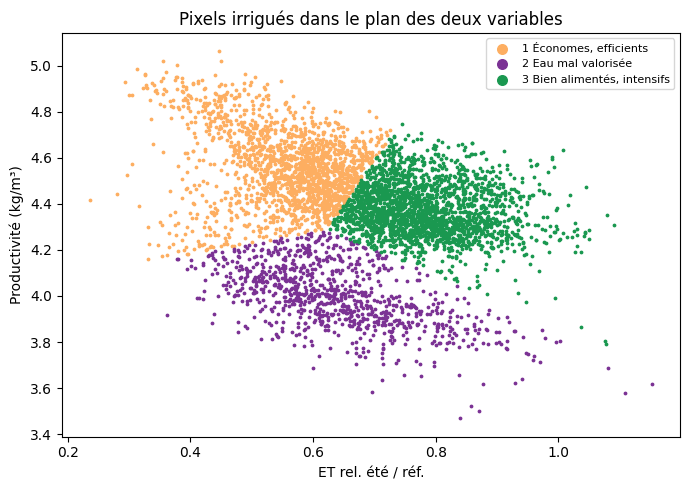

In [ ]:
# Niveau 2 : gestion de l'eau des pixels irrigués
irrigue = np.zeros((hauteur, largeur), dtype=bool)
irrigue[valides] = (groupes == 3)
pluvial = np.zeros((hauteur, largeur), dtype=bool)
pluvial[valides] = (groupes == 2)

noms2 = ["ET rel. été / réf.", "Productivité (kg/m³)"]
X2 = np.column_stack([carte_ete[irrigue], carte_pe[irrigue]])
print(f"Pixels irrigués : {X2.shape[0]} | corrélation : {np.corrcoef(X2.T)[0, 1]:.2f}")

X2_std = StandardScaler().fit_transform(X2)
inertie_tot2 = np.sum(X2_std ** 2)
for k in range(2, 7):
    km_k = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X2_std)
    s = silhouette_score(X2_std, km_k.labels_, sample_size=5000, random_state=0)
    print(f"k = {k} : silhouette = {s:.3f} | variance expliquée = {100 * (1 - km_k.inertia_ / inertie_tot2):.1f} %")

km2 = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X2_std)
ordre2 = np.argsort([X2[km2.labels_ == g, 0].mean() for g in range(3)])
sous_groupes = np.zeros_like(km2.labels_)
for nouveau, ancien in enumerate(ordre2):
    sous_groupes[km2.labels_ == ancien] = nouveau + 1

profil2 = pd.DataFrame(X2, columns=noms2)
profil2["AETI (mm/an)"] = carte_aeti[irrigue]
profil2["Irrigation (m³/ha)"] = carte_irri[irrigue] * 10
profil2["Sous-groupe"] = sous_groupes
resume2 = profil2.groupby("Sous-groupe").mean()
resume2["Surface (%)"] = 100 * profil2["Sous-groupe"].value_counts(normalize=True).sort_index()
resume2.index = ["1 Économes, efficients", "2 Eau mal valorisée", "3 Bien alimentés, intensifs"]
print("\nProfil moyen des sous-groupes irrigués :")
print(resume2.round(2))

print("\nCV de l'AETI par campagne :")
for c, aeti_c in zip(campagnes, liste_aeti):
    cv_tout = 100 * np.nanstd(aeti_c) / np.nanmean(aeti_c)
    cv_irr = 100 * np.nanstd(aeti_c[irrigue]) / np.nanmean(aeti_c[irrigue])
    print(f"  {nom_campagne[c]} : plein champ {cv_tout:.0f} % | irrigué seul {cv_irr:.0f} %")

carte_sg = np.full((hauteur, largeur), np.nan)
carte_sg[irrigue] = sous_groupes

couleurs_sg = ["#fdae61", "#7b3294", "#1a9850"]
ech = np.random.default_rng(0).choice(len(X2), size=min(5000, len(X2)), replace=False)
plt.figure(figsize=(7, 5))
for g, (coul, nom) in enumerate(zip(couleurs_sg, resume2.index), start=1):
    pts = ech[sous_groupes[ech] == g]
    plt.scatter(X2[pts, 0], X2[pts, 1], s=3, color=coul, label=nom)
plt.xlabel(noms2[0])
plt.ylabel(noms2[1])
plt.title("Pixels irrigués dans le plan des deux variables")
plt.legend(markerscale=4, fontsize=8)
plt.tight_layout()
plt.show()

## 5. Figures clés

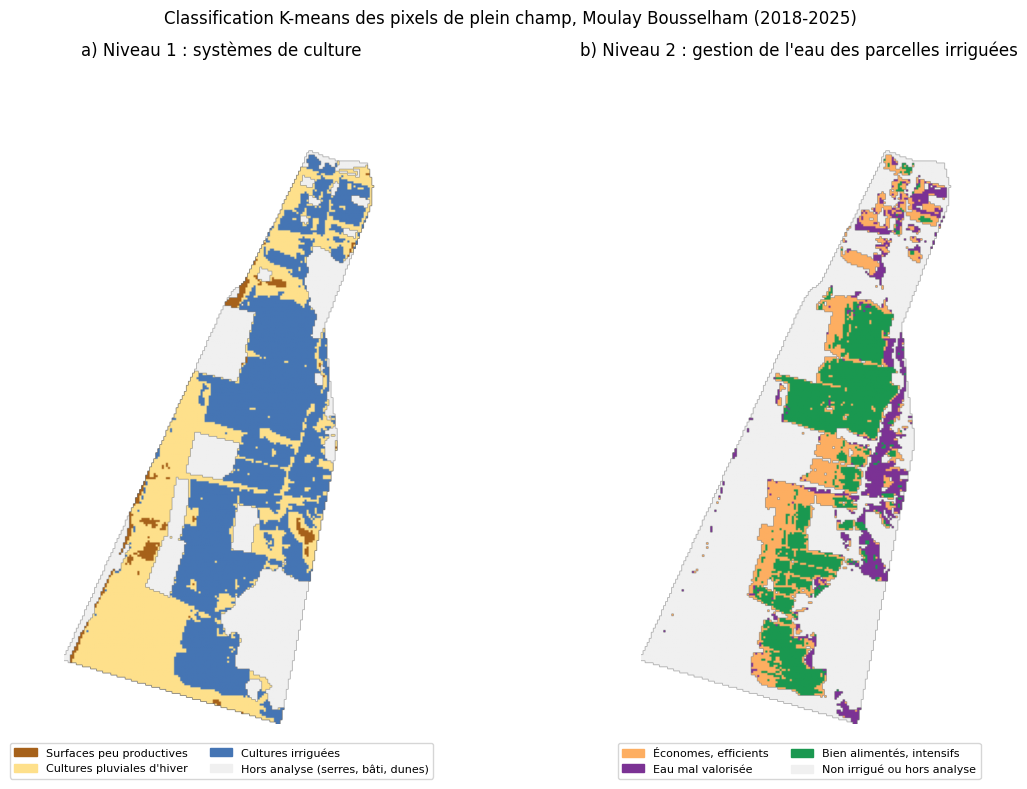

In [ ]:
# Figure 1 : carte des groupes (K-means en deux niveaux)
noms_n1 = ["Surfaces peu productives", "Cultures pluviales d'hiver", "Cultures irriguées"]
coul_n1 = ["#a6611a", "#fee08b", "#4575b4"]
noms_n2 = ["Économes, efficients", "Eau mal valorisée", "Bien alimentés, intensifs"]
coul_n2 = ["#fdae61", "#7b3294", "#1a9850"]

fond = np.where(dans_zone, 0, np.nan)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 8))

ax1.imshow(fond, cmap=ListedColormap(["#f0f0f0"]))
ax1.imshow(carte_groupes, cmap=ListedColormap(coul_n1), vmin=1, vmax=3)
ax1.legend(handles=[Patch(color=c, label=n) for c, n in zip(coul_n1, noms_n1)]
           + [Patch(color="#f0f0f0", label="Hors analyse (serres, bâti, dunes)")],
           loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=2, fontsize=8)
ax1.set_title("a) Niveau 1 : systèmes de culture")
ax1.axis("off")

ax2.imshow(fond, cmap=ListedColormap(["#f0f0f0"]))
ax2.imshow(carte_sg, cmap=ListedColormap(coul_n2), vmin=1, vmax=3)
ax2.legend(handles=[Patch(color=c, label=n) for c, n in zip(coul_n2, noms_n2)]
           + [Patch(color="#f0f0f0", label="Non irrigué ou hors analyse")],
           loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=2, fontsize=8)
ax2.set_title("b) Niveau 2 : gestion de l'eau des parcelles irriguées")
ax2.axis("off")

plt.suptitle("Classification K-means des pixels de plein champ, Moulay Bousselham (2018-2025)")
plt.tight_layout()
plt.savefig(dossier_projet + "/figure1_carte_groupes.png", dpi=200, bbox_inches="tight")
plt.show()

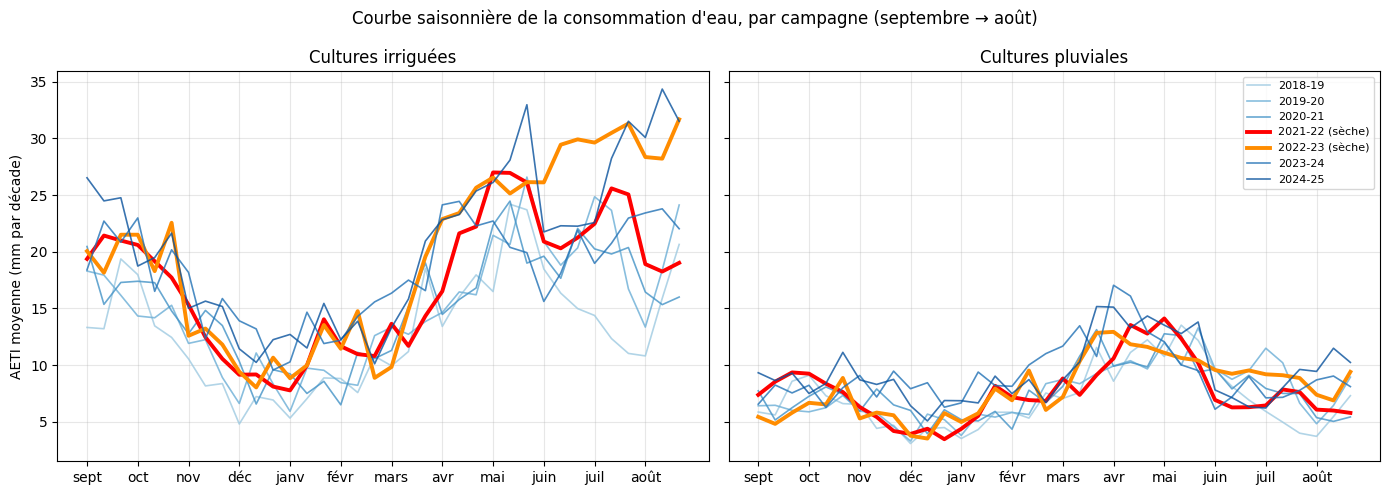

In [ ]:
# Figure 2 : courbe saisonnière par campagne, irrigué vs pluvial
mois_campagne = ["sept", "oct", "nov", "déc", "janv", "févr",
                 "mars", "avr", "mai", "juin", "juil", "août"]
couleurs_c = {2018: "#9ecae1", 2019: "#6baed6", 2020: "#4292c6",
              2021: "red", 2022: "darkorange", 2023: "#2171b5", 2024: "#08519c"}

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, masque, titre in [(axes[0], irrigue, "Cultures irriguées"),
                          (axes[1], pluvial, "Cultures pluviales")]:
    for c in campagnes:
        indices = np.where(campagne == c)[0]
        serie = [np.nanmean(aeti[i][masque]) for i in indices]
        epais = c in (2021, 2022)
        ax.plot(range(36), serie, color=couleurs_c[c], lw=2.8 if epais else 1.2,
                alpha=1 if epais else 0.8, label=nom_campagne[c] + (" (sèche)" if epais else ""))
    ax.set_xticks(range(0, 36, 3))
    ax.set_xticklabels(mois_campagne)
    ax.set_title(titre)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("AETI moyenne (mm par décade)")
axes[1].legend(fontsize=8)
plt.suptitle("Courbe saisonnière de la consommation d'eau, par campagne (septembre → août)")
plt.tight_layout()
plt.savefig(dossier_projet + "/figure2_courbe_saisonniere.png", dpi=200, bbox_inches="tight")
plt.show()

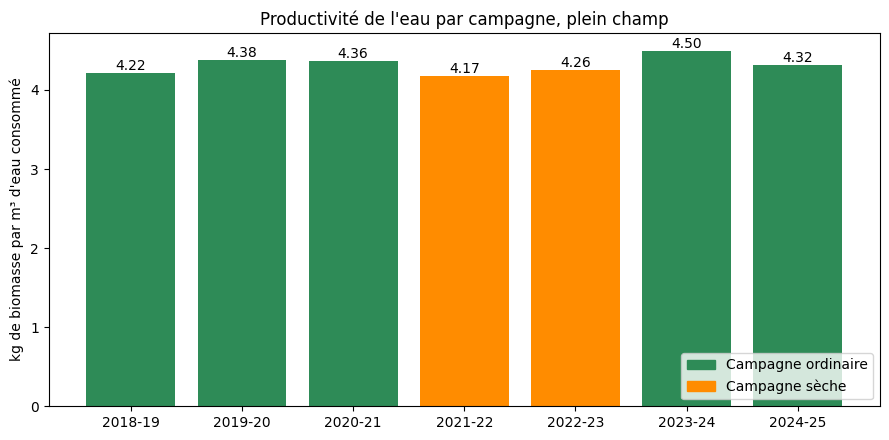

✅ Figures enregistrées dans /content/drive/MyDrive/Projet_WaPOR


In [ ]:
# Figure 3 : productivité de l'eau par campagne
couleurs_barres = ["darkorange" if c in (2021, 2022) else "seagreen" for c in campagnes]
plt.figure(figsize=(9, 4.5))
barres = plt.bar(tab_pe.index, tab_pe["Productivité (kg/m³)"], color=couleurs_barres)
plt.bar_label(barres, fmt="%.2f")
plt.legend(handles=[Patch(color="seagreen", label="Campagne ordinaire"),
                    Patch(color="darkorange", label="Campagne sèche")], loc="lower right")
plt.ylabel("kg de biomasse par m³ d'eau consommé")
plt.title("Productivité de l'eau par campagne, plein champ")
plt.tight_layout()
plt.savefig(dossier_projet + "/figure3_productivite_eau.png", dpi=200, bbox_inches="tight")
plt.show()
print("✅ Figures enregistrées dans", dossier_projet)

## 6. Conclusions et limites

### Réponse à la problématique
- **Où ?** Le plein champ se partage entre un **cœur irrigué** au centre (≈ 55 % des pixels classés) et des **cultures pluviales d'hiver** à l'ouest et au sud-ouest (≈ 43 %). Parmi les irrigués : 45 % **bien alimentés**, 36 % **économes et efficients**, 19 % à **eau mal valorisée**, surtout en bordure de lagune.
- **Quand ?** Les écarts se jouent **de mai à août** et seulement pour les cultures irriguées ; en hiver, pluie et faible demande climatique rendent les situations semblables.
- **Assez, trop, pas assez ?** Pas de pénurie généralisée : pendant la sécheresse, l'irrigation a **compensé** la baisse de pluie (2021-22 : pluie ÷ 2, irrigation + 38 %). La consommation augmente sur toute la période (≈ 3 900 → 5 600 m³/ha), avec une productivité de l'eau **stable** (4,2-4,5 kg/m³), en léger recul les années sèches. L'uniformité entre irrigants s'améliore (CV 39 % → ≈ 20 %).
- **La sécheresse vue à l'échelle de la saison.** Été 2022 : l'irrigation décroche dès juin. Été 2023 : elle est maintenue au niveau le plus haut de la période.

### Choix de méthode
- Occupation du sol Esri (LCC absente de WaPOR v3) et digitalisation manuelle des serres.
- Analyse par campagne agricole (septembre → août).
- Seuil de 0,7 remplacé par une référence locale (95e percentile), car même les meilleures parcelles ne l'atteignent pas en été.
- K-means en deux niveaux sur des variables non redondantes, validé par le coude et la silhouette (0,52 et 0,43).

### Limites
- RET et pluie à résolution grossière (une valeur par décade pour toute la zone), RET probablement surestimée en bord de mer.
- Sous serre, l'AETI est sous-estimée : serres exclues des indicateurs.
- Biomasse WaPOR totale (racines comprises) : valeurs absolues de productivité à prendre avec prudence.
- Carte Esri absente pour 2024-2025 (carte 2023 réutilisée) et changement de classification en 2022-2023.
- Zone délimitée visuellement, sans les limites officielles du périmètre (ORMVA du Loukkos).
- Irrigation estimée = eau consommée ; l'eau prélevée (nappe) n'est pas observée.